#Introduction to Linear Algebra and the world of probablitites

In this work-sheet, we shall do two activities. First of all we shall check the power of SVD. Then we shall check how may we generate data from an arbitrary distribution (given that we have the ability to generate data from a uniform distribution).

##Singular Value Decomposition
Lets load an image and try to do it's SVD.

Please note the way to access an image from your Google drive. Change the code accordingly (and load an image in your Google drive) to access to your own image!

Mark that we shall be using PIL's Image library, a useful set of powerful algorithms for image processing.


In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import time

from PIL import Image

In [2]:
from pathlib import Path

IMAGE_PATH = Path("data/urban.jpeg")  # satellite: urban (Warsaw)
assert IMAGE_PATH.exists(), f"Missing image: {IMAGE_PATH.resolve()}"


Lets load the image and convert that to a gray-scale version (so that we can treat it just like a 2D matrix). What will happen if its not gray-scale?

Mark how we have used the command $matrix$ to generate a matrix from the image!

In [3]:
img = Image.open(IMAGE_PATH)
imggray = img.convert('L')


/var/folders/mq/shn2n9dj3810xjv9d07j1f3h0000gn/T/ipykernel_61585/1016122045.py:1: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  imgmat = np.array(list(imggray.getdata(band=0)), float)
/var/folders/mq/shn2n9dj3810xjv9d07j1f3h0000gn/T/ipykernel_61585/1016122045.py:2: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  imgmat.shape = (imggray.size[1], imggray.size[0])


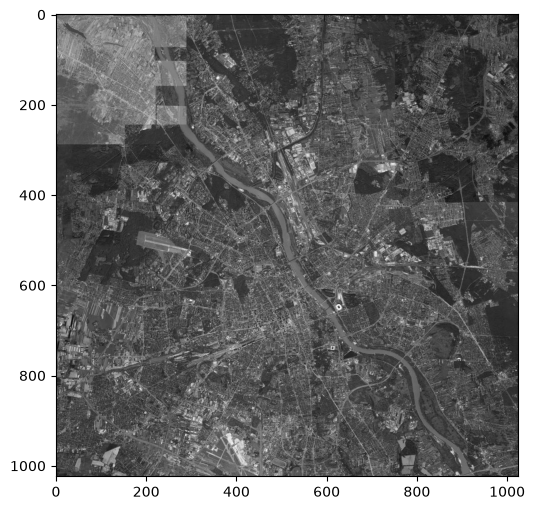

In [4]:
imgmat = np.array(list(imggray.getdata(band=0)), float)
imgmat.shape = (imggray.size[1], imggray.size[0])
imgmat = np.matrix(imgmat)
plt.figure(figsize=(9,6))
plt.imshow(imgmat, cmap='gray')


###SVD

We can directly use the $svd$ command from Numpy to operate SVD on the matrix.

Lets first check how the image will look if we only use a single vector to reconstruct the image.

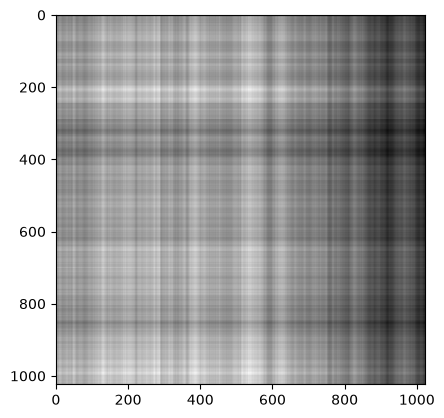

In [5]:
U, sigma, V = np.linalg.svd(imgmat)
reconstimg = np.matrix(U[:, :1]) * np.diag(sigma[:1]) * np.matrix(V[:1, :])
plt.imshow(reconstimg, cmap='gray');



Now lets check how does the sigma vector look like.

What do you observe? How many vecotrs can we use to get a decent reconstruction of the image?
What will happen if we omit the first 1-2 vectors (corresponding to the largest eigen values)?

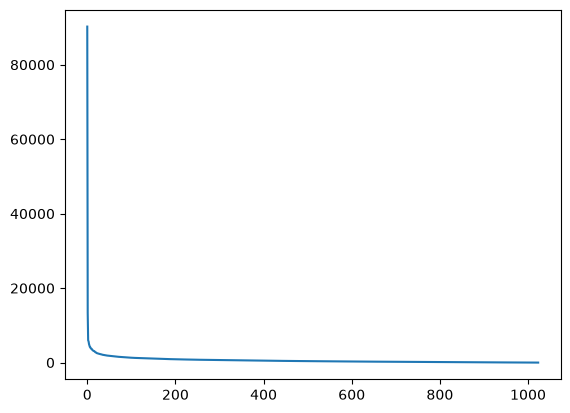

In [6]:
U.shape
sigma.shape
plt.plot(sigma)


### Observations (urban satellite image)

**What do you observe on `sigma`?**  
The singular values drop very quickly: the first few are huge, then the curve flattens near zero. Most of the image energy is in a small number of leading components.

**How many vectors are good enough?**  
For this urban scene, about **50–70** leading components already give a decent reconstruction. `k=5` is too coarse; `k=20` starts to look like the city; beyond ~70 the visual gain is small.

**What if we omit the first 1–2 vectors?**  
Quality gets worse (not better): we lose global brightness / main structure. The largest singular values are the most important ones.



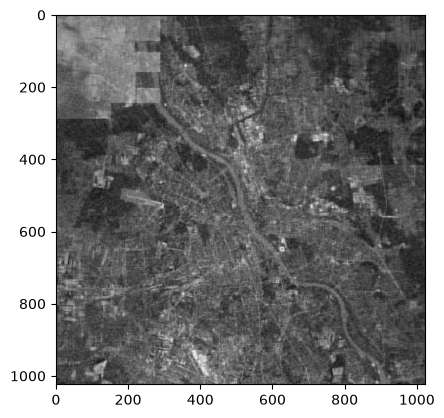

In [7]:
i = 70
j = 0
reconstimg = np.matrix(U[:, j:i]) * np.diag(sigma[j:i]) * np.matrix(V[j:i, :])
plt.imshow(reconstimg, cmap='gray');


### Largest k vs 10th, 11th, …, k+10

Assignment question: instead of the largest `k` eigenvalues/singular values, if we use the 10th, 11th, …, `(k+10)`th — do we get better images?



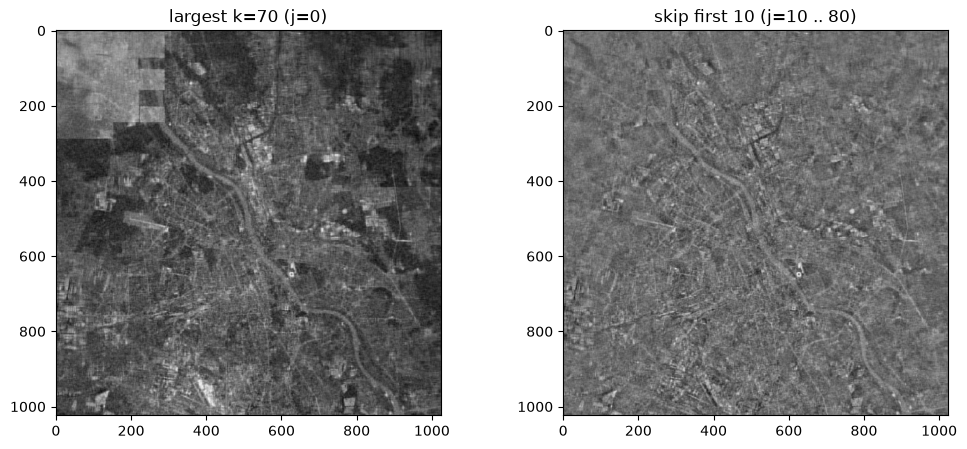

In [8]:
# same number of components k, but skip the first 10
k = 70
# largest k: j=0, i=k
reconst_largest = np.matrix(U[:, 0:k]) * np.diag(sigma[0:k]) * np.matrix(V[0:k, :])
# 10 .. k+10
reconst_skip10 = np.matrix(U[:, 10:k+10]) * np.diag(sigma[10:k+10]) * np.matrix(V[10:k+10, :])

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.imshow(reconst_largest, cmap='gray')
plt.title(f'largest k={k} (j=0)')
plt.subplot(1,2,2)
plt.imshow(reconst_skip10, cmap='gray')
plt.title(f'skip first 10 (j=10 .. {k+10})')
plt.show()


**Answer:** No — images are **worse**, not better.  
Skipping the first 10 removes the most informative components (brightness + main layout). Keeping the same count `k` but starting at the 10th cannot beat using the largest `k`.



### Different terrains: forest / urban / ocean

Load satellite images of different terrains and check how many singular values are enough without clear perceptual degradation.



/var/folders/mq/shn2n9dj3810xjv9d07j1f3h0000gn/T/ipykernel_61585/3370484543.py:3: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  mat = np.array(list(img.getdata(band=0)), float)
/var/folders/mq/shn2n9dj3810xjv9d07j1f3h0000gn/T/ipykernel_61585/3370484543.py:4: DeprecationWarning: Setting the shape on a NumPy array has been deprecated in NumPy 2.5.
As an alternative, you can create a new view using np.reshape (with copy=False if needed).
  mat.shape = (img.size[1], img.size[0])


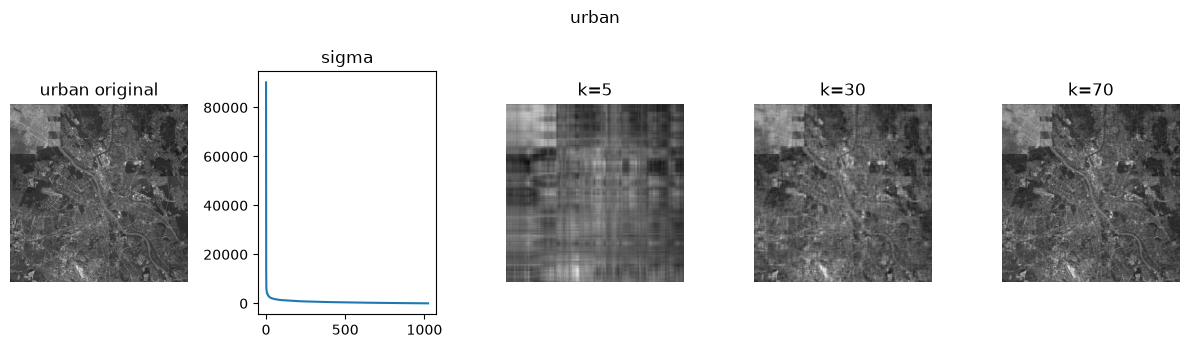

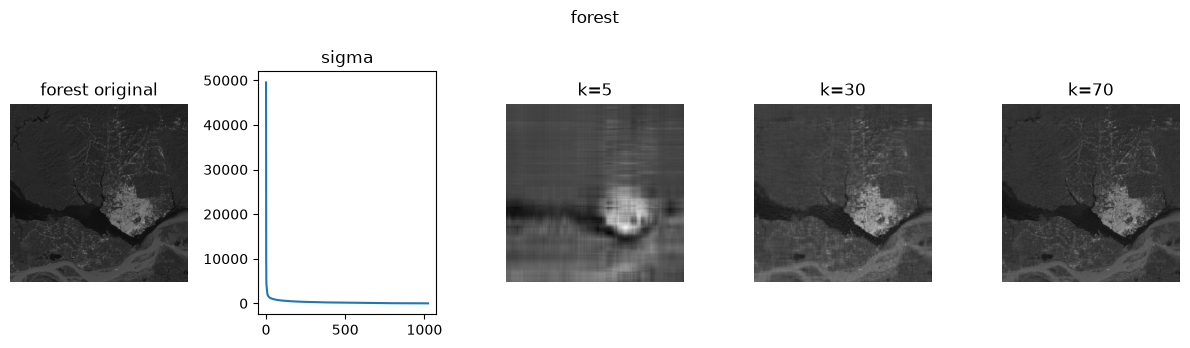

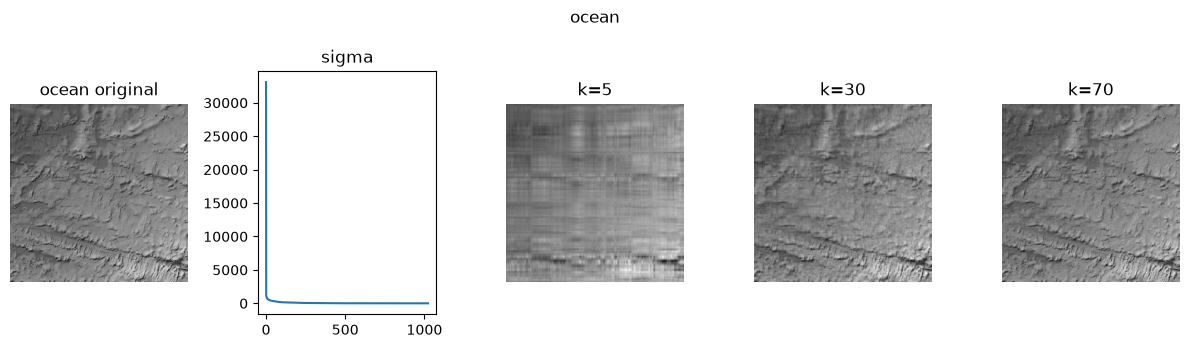

In [9]:
def run_svd_preview(path, title, ks=(5, 30, 70)):
    img = Image.open(path).convert('L')
    mat = np.array(list(img.getdata(band=0)), float)
    mat.shape = (img.size[1], img.size[0])
    mat = np.matrix(mat)
    U, sigma, V = np.linalg.svd(mat)

    plt.figure(figsize=(12, 3.5))
    plt.subplot(1, len(ks)+2, 1)
    plt.imshow(mat, cmap='gray')
    plt.title(f'{title} original')
    plt.axis('off')
    plt.subplot(1, len(ks)+2, 2)
    plt.plot(sigma)
    plt.title('sigma')
    for t, k in enumerate(ks):
        rec = np.matrix(U[:, :k]) * np.diag(sigma[:k]) * np.matrix(V[:k, :])
        plt.subplot(1, len(ks)+2, t+3)
        plt.imshow(rec, cmap='gray')
        plt.title(f'k={k}')
        plt.axis('off')
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()
    return sigma

sigma_urban = run_svd_preview(Path('data/urban.jpeg'), 'urban')
sigma_forest = run_svd_preview(Path('data/forest.jpeg'), 'forest')
sigma_ocean = run_svd_preview(Path('data/ocean.jpeg'), 'ocean')


### Observations — terrains

| Terrain | Roughly enough `k` | Comment |
|---|---|---|
| **Ocean** | fewer components | smoother / low texture → easier low-rank approx. |
| **Forest** | mid | repeated canopy texture |
| **Urban** | more (~50–70) | sharp edges, streets, buildings |

**Summary:** how many singular values you need depends on the terrain. Ocean usually needs the fewest; urban needs the most to avoid perceptual degradation.

